# Diagnóstico de cancro da mama — Exploração dos dados

**Inteligência Artificial Centrada no Humano** · Mestrado em Inteligência Artificial e Engenharia de Dados · FCTUC

Conhecer o dataset antes de treinar: quantas imagens há por classe, como são, e quanta memória ocupam consoante o tamanho escolhido (ponto levantado pelo professor: as imagens podem ser pesadas e pode ser preciso limitar o dataset).

## 1. Configuração

Importa o código partilhado de `src/` e os caminhos de `src/config.py`. Este notebook não treina modelos, por isso não usa a GPU.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent   # raiz do repositório (o notebook está em notebooks/)
sys.path.insert(0, str(ROOT))

from src.config import DATA_PATH, RESULTS_PATH

## 2. Distribuição das classes

O dataset é o [Breast Ultrasound Images](https://datasetninja.com/breast-ultrasound-images): ecografias mamárias de mulheres entre os 25 e os 75 anos, divididas em três classes:
- **normal**: sem lesão;
- **benign**: lesão benigna (não cancerígena);
- **malignant**: lesão maligna (cancro).

A classe de cada imagem vem do nome do ficheiro (ex.: `benign (12).png`).

### Imagens repetidas
O dataset tem **muitas imagens repetidas**: a mesma ecografia guardada em dois ou mais ficheiros, às vezes com um recorte ligeiramente diferente. Comparar os ficheiros byte a byte só encontra uma (`benign (433).png` = `malignant (145).png`), por isso `find_duplicates` (em `src/data.py`) compara as próprias imagens: reduz cada uma a 32×32 píxeis e considera duas imagens a mesma se a correlação entre os píxeis for maior do que 0.95.

Isto tem duas consequências:
1. **Data leakage escondido**, se uma cópia ficar no treino e outra no teste. Por isso as cópias ficam sempre no mesmo conjunto (notebook 01, secção 2).
2. **Labels contraditórias.** Alguns grupos têm a mesma imagem com classes diferentes (ex.: benigna num ficheiro e maligna noutro). Como não se sabe qual está certa, essas imagens são todas excluídas.

Total: 780 imagens {'normal': 133, 'benign': 437, 'malignant': 210}


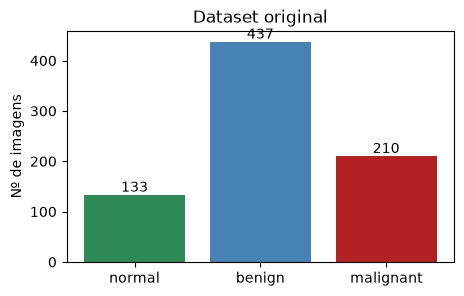

780 ficheiros, 601 ecografias diferentes
Nº de grupos por tamanho (1 = imagem única, 2 = repetida duas vezes, ...): {1: 462, 2: 112, 3: 20, 4: 5, 7: 2}
Imagens excluídas por terem labels contraditórias (19): ['benign (131).png', 'benign (164).png', 'benign (269).png', 'benign (333).png', 'benign (399).png', 'benign (406).png', 'benign (42).png', 'benign (433).png', 'benign (435).png', 'benign (437).png', 'benign (85).png', 'malignant (145).png', 'malignant (51).png', 'malignant (52).png', 'malignant (77).png', 'malignant (93).png', 'malignant (94).png', 'normal (1).png', 'normal (34).png']


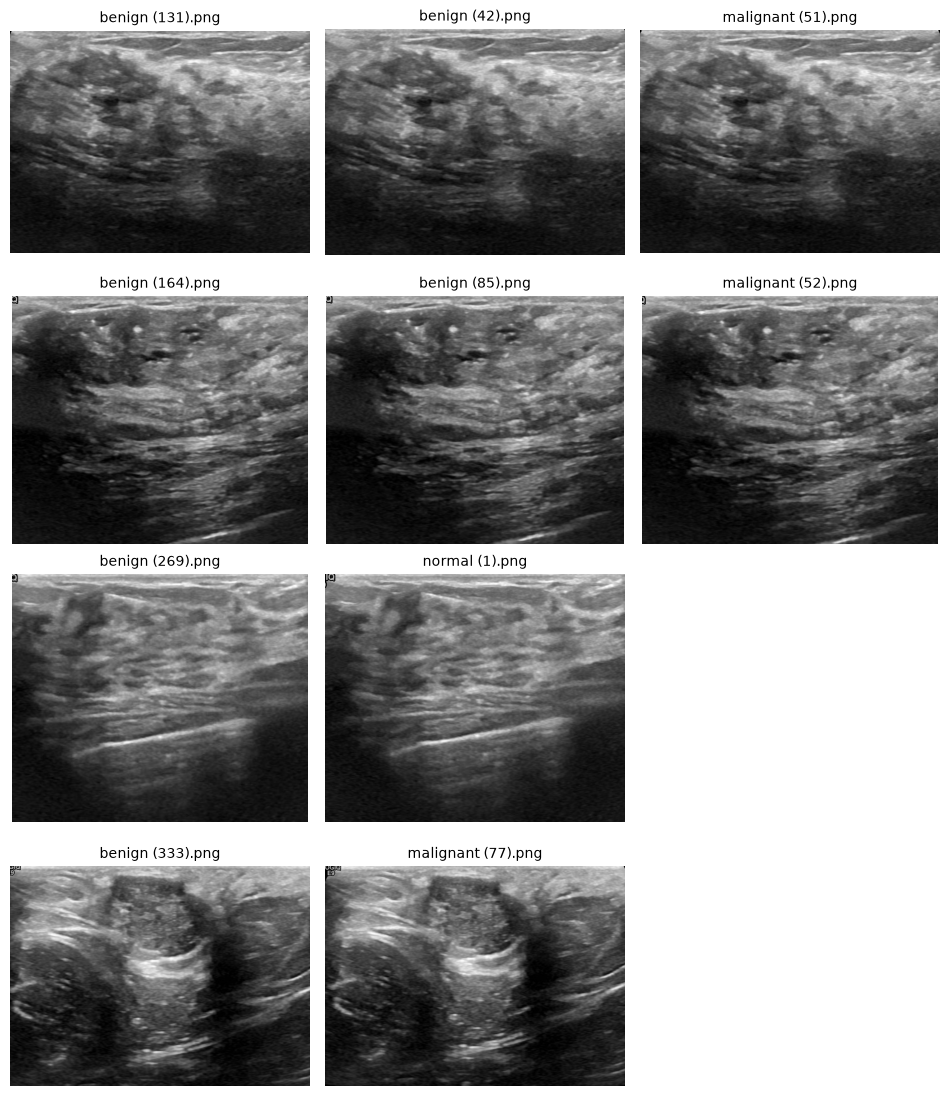

In [2]:
from src.exploration import class_counts, list_images, plot_class_distribution

names, labels = list_images(DATA_PATH)
counts = class_counts(labels)
print(f"Total: {len(names)} imagens", counts)
plot_class_distribution(counts, "Dataset original")

from collections import Counter
from src.data import find_duplicates
from src.exploration import plot_duplicate_groups

groups, conflicts = find_duplicates(DATA_PATH)
sizes = Counter(Counter(groups.values()).values())
print(f"{len(groups)} ficheiros, {len(set(groups.values()))} ecografias diferentes")
print("Nº de grupos por tamanho (1 = imagem única, 2 = repetida duas vezes, ...):", dict(sorted(sizes.items())))
print(f"Imagens excluídas por terem labels contraditórias ({len(conflicts)}):", sorted(conflicts))

conflict_groups = {}
for name in sorted(conflicts):
    conflict_groups.setdefault(groups[name], []).append(name)
plot_duplicate_groups(DATA_PATH, list(conflict_groups.values()))

Cada linha acima é **a mesma ecografia** em ficheiros diferentes, com classes diferentes no nome. Também foram encontradas quando o modelo do notebook 01 mostrava dois "cancros não detetados" iguais.

O dataset é desequilibrado: há mais do triplo de imagens benignas do que normais. Sem balanceamento, o modelo tende a favorecer a classe maioritária: pode acertar muito só por dizer "benigno" quase sempre, e falhar justamente os casos malignos, que são os que mais importam.

## 3. Exemplos de imagens

Algumas imagens aleatórias de cada classe. Repara que as diferenças entre classes não são óbvias a olho nu: as lesões aparecem como zonas escuras, e a forma e os contornos (regulares ou irregulares) são o que distingue uma lesão benigna de uma maligna. Algumas imagens têm também anotações do ecógrafo (texto, marcas), que o modelo pode aprender por engano — é uma das razões para usar explicabilidade (Grad-CAM) mais tarde.

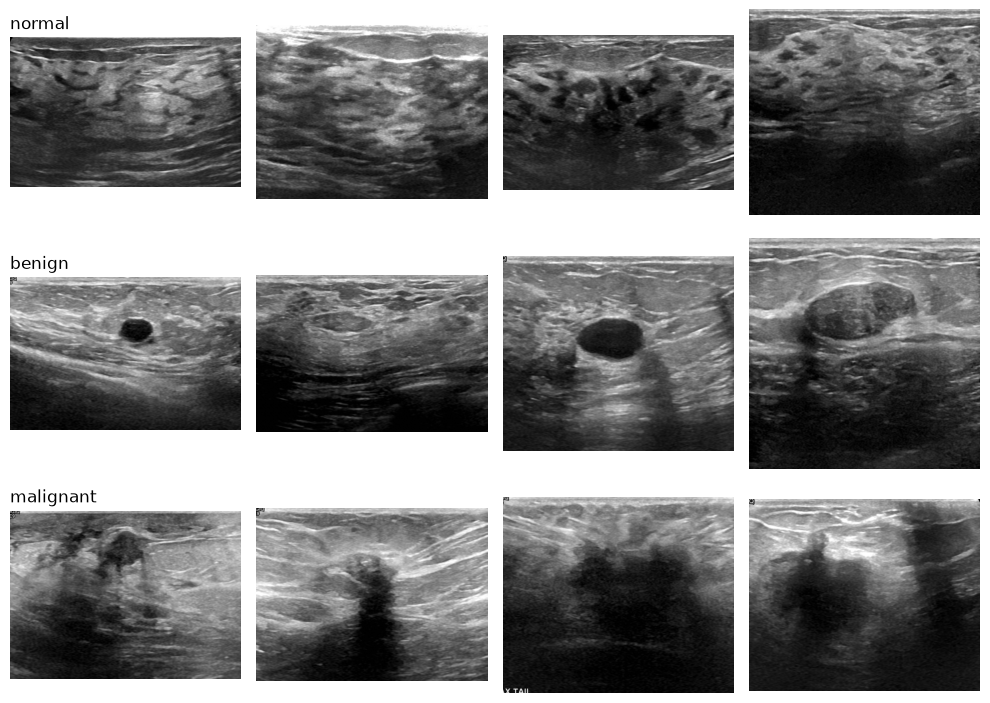

In [3]:
from src.exploration import plot_examples

plot_examples(DATA_PATH, names, labels, per_class=4)

## 4. Balanceamento

Só o treino é balanceado, depois da divisão (o porquê está na secção 2 do notebook 01), com rotações e reflexões (`src/data.py`):

| Classe | Imagens originais | Cópias acrescentadas | Fator |
|---|---|---|---|
| normal | 133 | 5 (2 rotações, 1 reflexão, 2 rotações com reflexão) | ×6 |
| malignant | 210 | 3 (1 rotação, 1 reflexão, 1 rotação com reflexão) | ×4 |
| benign | 437 | 1 (reflexão) | ×2 |

Rodar ou espelhar uma ecografia não muda o diagnóstico, por isso estas cópias são exemplos válidos e dão ao modelo mais variedade.

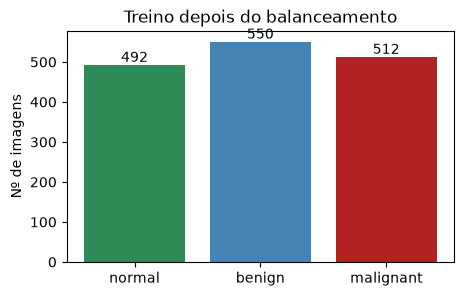

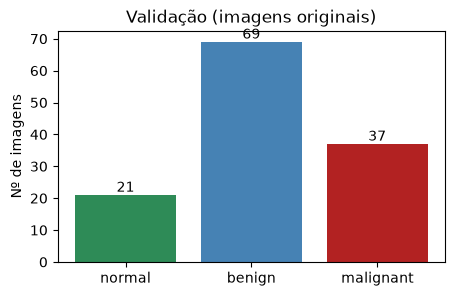

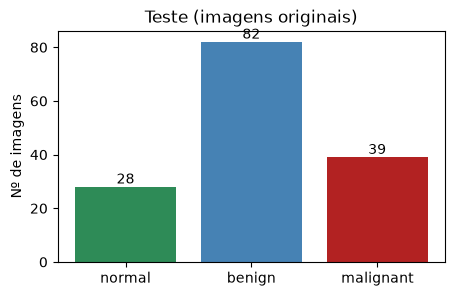

In [4]:
from src.data import load_dataset

IMG_SIZE = 64   # pequeno, só para ver as contagens rapidamente
x_train, x_val, x_test, y_train, y_val, y_test = load_dataset(DATA_PATH, size=IMG_SIZE)
plot_class_distribution(class_counts(list(y_train)), "Treino depois do balanceamento")
plot_class_distribution(class_counts(list(y_val)), "Validação (imagens originais)")
plot_class_distribution(class_counts(list(y_test)), "Teste (imagens originais)")

## 5. Tamanho das imagens e memória

As imagens originais têm tamanhos diferentes, mas uma CNN precisa que todas as entradas tenham o mesmo tamanho. Por isso são todas redimensionadas para `IMG_SIZE × IMG_SIZE` (quadradas) no carregamento. Quanto maior o `IMG_SIZE`, mais detalhe se mantém, mas mais memória e tempo de treino são precisos.

A segunda célula mostra a memória ocupada só pelas imagens (cada píxel é um `float32` = 4 bytes, 1 canal porque é escala de cinzento), sem contar o modelo nem o treino, que usam bastante mais. Para referência: o computador tem cerca de 13 GB de RAM e a GPU (RTX 3050) tem 4 GB.

In [5]:
import numpy as np
from src.exploration import original_sizes

sizes = original_sizes(DATA_PATH, names)
print(f"Largura: {sizes[:, 0].min()}–{sizes[:, 0].max()} px (mediana {int(np.median(sizes[:, 0]))})")
print(f"Altura:  {sizes[:, 1].min()}–{sizes[:, 1].max()} px (mediana {int(np.median(sizes[:, 1]))})")

Largura: 190–1048 px (mediana 564)
Altura:  310–719 px (mediana 474)


In [6]:
from src.exploration import memory_mb

n_images = len(x_train) + len(x_val) + len(x_test)
for size in [64, 128, 224]:
    print(f"{size}×{size}: {memory_mb(n_images, size):6.0f} MB")

64×64:     30 MB
128×128:    120 MB
224×224:    367 MB


## 6. Conclusões

- **780 ficheiros, mas só 601 ecografias diferentes.** 112 ecografias aparecem 2 vezes, 20 aparecem 3 vezes, 5 aparecem 4 vezes e 2 aparecem 7 vezes. Isto não vem na descrição do dataset e só se descobre comparando as imagens.
- **19 imagens excluídas** por labels contraditórias (a mesma ecografia como benigna e maligna, ou benigna e normal). Ficam **761 imagens**: 131 normais, 426 benignas e 204 malignas.
- **O dataset é desequilibrado**: o treino é balanceado e as métricas olham para cada classe (recall, F1), não só para a accuracy.
- **Tamanho de imagem: 128×128.** As imagens ocupam ~120 MB, o que cabe bem na RAM e na GPU de 4 GB. 224×224 não melhorou os resultados (experiências preliminares, no relatório) e gasta 3× mais memória. Não é preciso limitar o dataset.